# Malaria Cell Classification

Binary classification of segmented blood cell images (parasitized vs uninfected) with a retrainable pipeline.

In [1]:
import os
import sys
import zipfile
from pathlib import Path
from google.colab import files

uploaded = files.upload()
with zipfile.ZipFile(next(iter(uploaded))) as bundle:
    bundle.extractall("/content")

root = Path("/content/malaria-classifier")
os.chdir(root)
sys.path.insert(0, str(root))

Saving malaria-classifier.zip to malaria-classifier.zip


In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn import metrics as skm

from src import config
from src import model as M
from src import preprocessing as P
from src import retrain as R

tf.keras.utils.set_random_seed(config.SEED)
sns.set_theme(style="whitegrid")
print(tf.__version__, keras.__version__)

2.21.0 3.13.2


In [3]:
P.download_dataset()
P.split_dataset()

train_paths, train_labels = P.list_labelled_files(config.TRAIN_DIR)
test_paths, test_labels = P.list_labelled_files(config.TEST_DIR)
names = dict(enumerate(config.CLASS_NAMES))

counts = pd.DataFrame(
    {
        "train": pd.Series(train_labels).map(names).value_counts(),
        "test": pd.Series(test_labels).map(names).value_counts(),
    }
)
counts

,train,test
uninfected,11024,2755
parasitized,11024,2755


Class balance across the train and test splits.

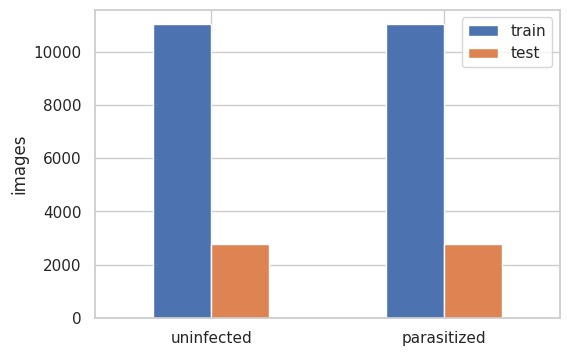

In [4]:
counts.plot(kind="bar", figsize=(6, 4))
plt.ylabel("images")
plt.xticks(rotation=0)
plt.show()

Both splits are perfectly balanced, with 11,024 images per class in training and 2,755 per class in testing, so accuracy is a fair headline number. Recall on parasitized cells is still reported separately because a missed infection costs more than a false alarm.

Random cells from each class (top row parasitized, bottom row uninfected).

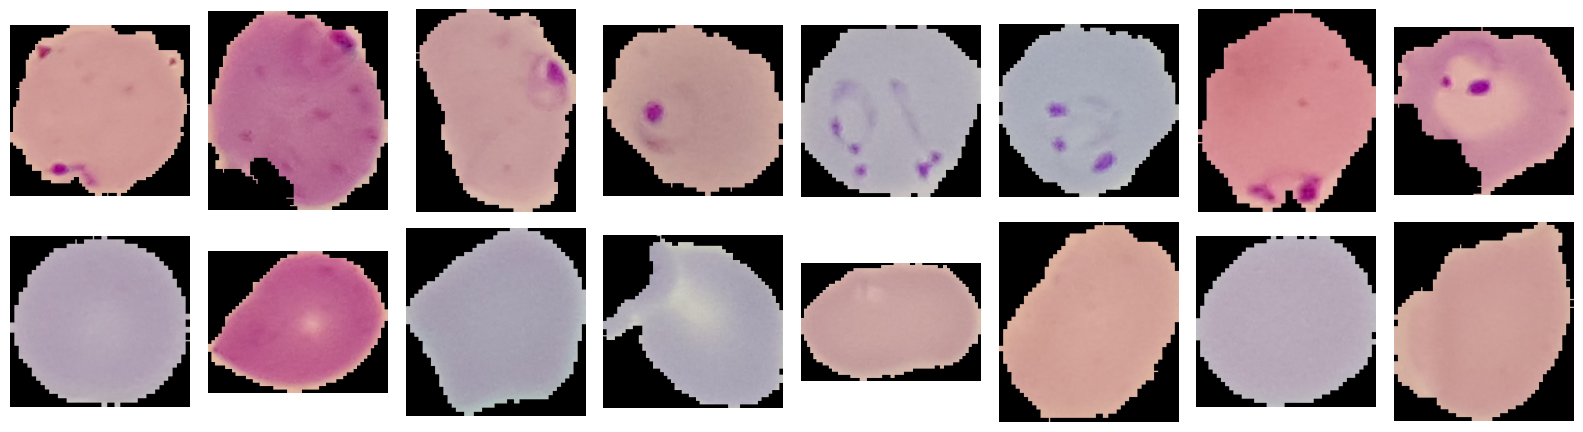

In [5]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, label in enumerate((1, 0)):
    pool = [p for p, l in zip(train_paths, train_labels) if l == label]
    for ax, path in zip(axes[row], rng.choice(pool, 8, replace=False)):
        ax.imshow(Image.open(path))
        ax.axis("off")
plt.tight_layout()
plt.show()

Parasites appear as small, dark purple spots, while the rest of the cell looks much the same in both classes. The overall colour varies widely, from pale grey-blue to pink and orange, which points to different slides or staining batches rather than infection status.

Per-image features measured on cell pixels only (the black background is excluded): dimensions, channel means, saturation and the fraction of low-green (stained) pixels.

In [6]:
rng = np.random.default_rng(config.SEED)
rows = []
for label, name in enumerate(config.CLASS_NAMES):
    pool = [p for p, l in zip(train_paths, train_labels) if l == label]
    for path in rng.choice(pool, 1500, replace=False):
        rows.append({"class": name, **P.image_features(path)})
features = pd.DataFrame(rows)
features.groupby("class").mean().round(3).T

class,parasitized,uninfected
width,133.630,131.478
height,134.656,132.358
cell_fraction,0.710,0.724
mean_r,189.936,188.301
mean_g,145.587,155.991
mean_b,157.944,164.115
saturation,0.260,0.203
stain_fraction,0.045,0.005


Width and height by class. Every image is resized to 128x128 before training.

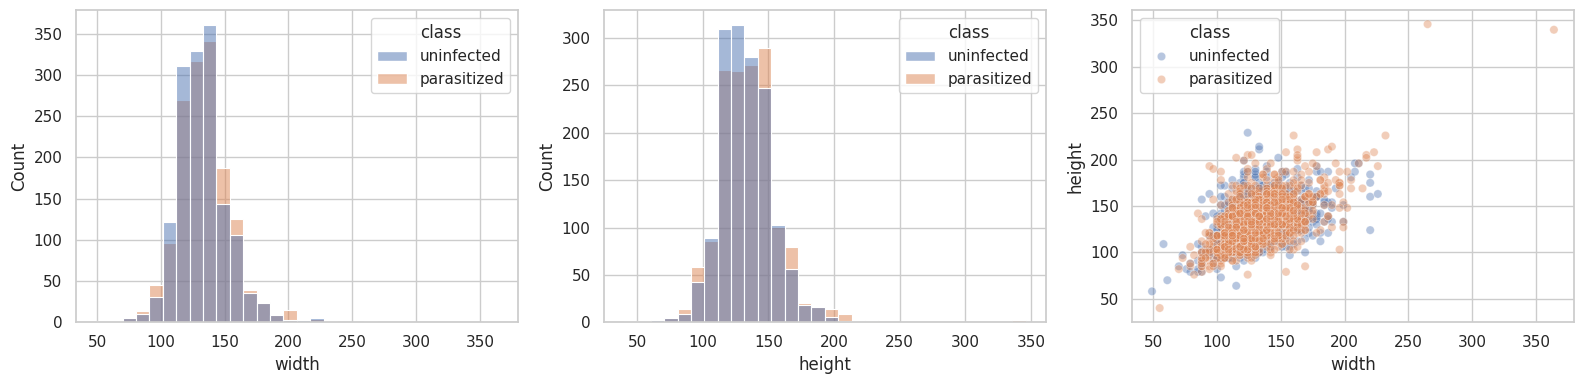

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=features, x="width", hue="class", bins=30, ax=axes[0])
sns.histplot(data=features, x="height", hue="class", bins=30, ax=axes[1])
sns.scatterplot(data=features, x="width", y="height", hue="class", alpha=0.4, ax=axes[2])
plt.tight_layout()
plt.show()

Width and height are almost identical across classes (about 132 to 135 pixels on average), apart from two outliers above 250 pixels. Size carries almost no signal (Cohen's d around 0.1), so resizing every image to 128x128 loses little.

Mean red, green and blue intensity over cell pixels, by class.

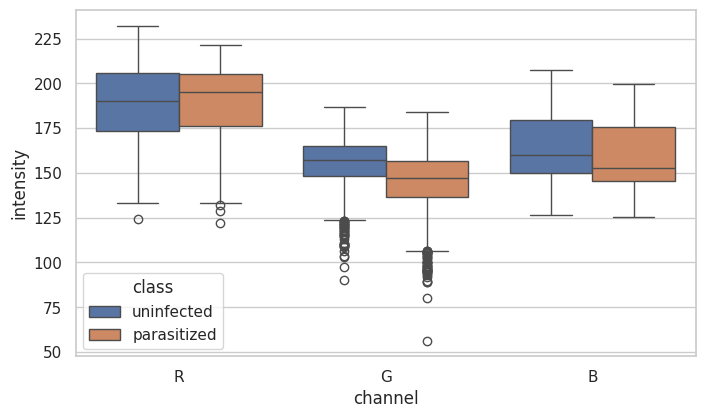

In [8]:
channels = features.melt(
    id_vars="class", value_vars=["mean_r", "mean_g", "mean_b"], var_name="channel", value_name="intensity"
)
channels["channel"] = channels["channel"].str[-1].str.upper()
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=channels, x="channel", y="intensity", hue="class")
plt.show()

The green channel separates the classes best, with a mean of 145.6 for parasitized cells against 156.0 for uninfected ones, which fits a stain that absorbs green light. Red is nearly identical and blue is slightly lower in infected cells. The boxes overlap heavily, so no single channel can classify a cell on its own.

Fraction of stained (low-green) cell pixels and mean saturation, by class.

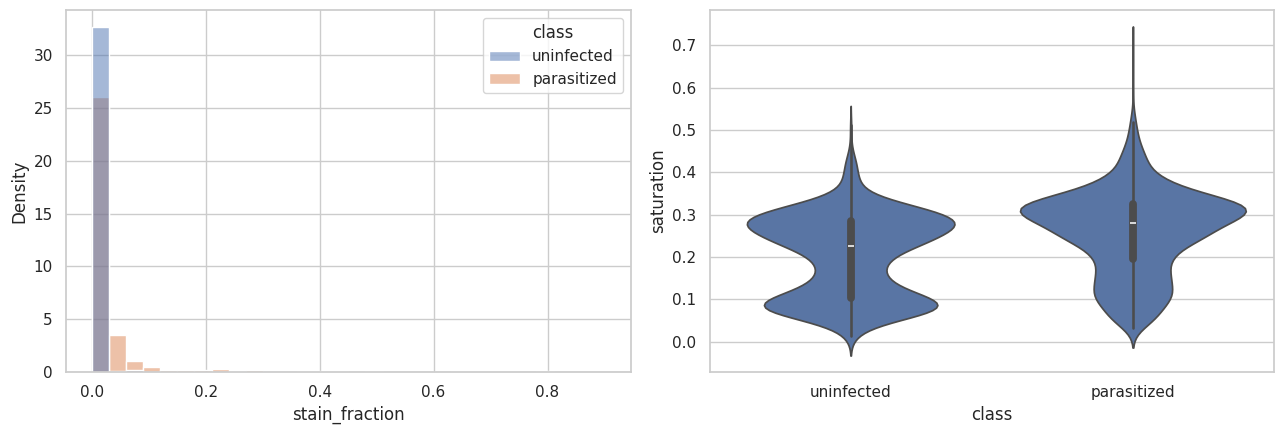

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(
    data=features, x="stain_fraction", hue="class", bins=30, stat="density", common_norm=False, ax=axes[0]
)
sns.violinplot(data=features, x="class", y="saturation", ax=axes[1])
plt.tight_layout()
plt.show()

Stained pixels are rare but clearly more common in parasitized cells (mean fraction 0.045 against 0.005), so the parasite covers only a few percent of the cell. Saturation has two peaks in both classes, which matches the colour differences between slides seen in the sample grid, and infected cells sit higher on average (0.26 against 0.20).

Correlation between the image features.

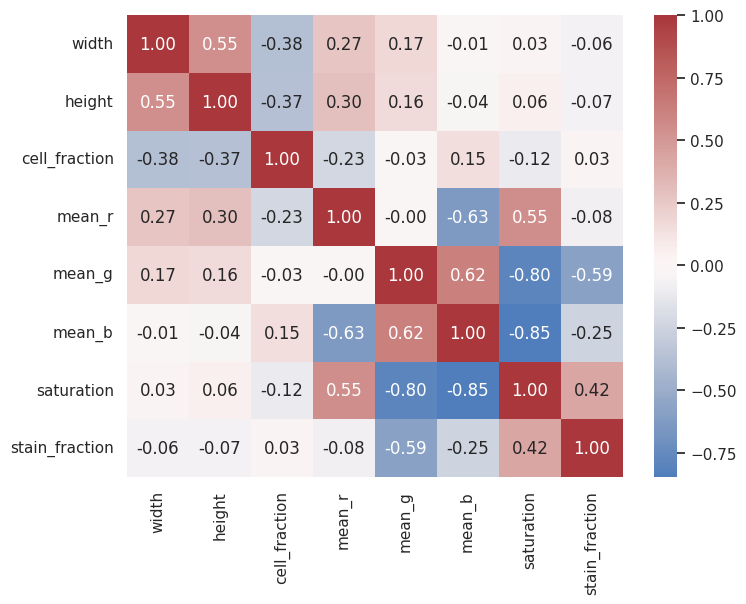

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(features.drop(columns="class").corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.show()

Saturation is strongly tied to the green and blue channels (correlations of -0.80 and -0.85), so these features mostly repeat the same colour information. Width and height move together (0.55) but are unrelated to colour.

Standardised mean difference between classes (Cohen's d, positive means higher in parasitized cells), used to rank how well each feature separates them.

In [11]:
def cohens_d(df, column):
    a = df.loc[df["class"] == "parasitized", column]
    b = df.loc[df["class"] == "uninfected", column]
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled


effect_sizes = pd.Series({c: cohens_d(features, c) for c in features.columns.drop("class")})
effect_sizes.sort_values(key=abs, ascending=False).round(3)

,0
mean_g,-0.663
saturation,0.577
stain_fraction,0.457
mean_b,-0.377
cell_fraction,-0.247
height,0.109
width,0.104
mean_r,0.084


Mean green has the largest effect (d = -0.66), followed by saturation (0.58) and stain fraction (0.46), all medium effects, while the size features are negligible. No hand-built feature separates the classes cleanly, because the parasite is a small local structure and colour also varies by slide. That is why a model that learns local patterns is needed.

In [12]:
tr_p, tr_l, va_p, va_l = P.train_val_split(train_paths, train_labels)
train_ds = P.make_dataset(tr_p, tr_l, shuffle=True)
val_ds = P.make_dataset(va_p, va_l)
test_ds = P.make_dataset(test_paths, test_labels)
len(tr_p), len(va_p), len(test_paths)

(18740, 3308, 5510)

Small CNN configurations.

In [13]:
CNN_BASELINE = {
    "name": "cnn_baseline",
    "arch": "cnn_baseline",
    "augment": False,
    "dropout": 0.0,
    "lr": 1e-3,
    "epochs": 15,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

CNN_IMPROVED = {
    "name": "cnn_improved",
    "arch": "cnn_improved",
    "augment": True,
    "dropout": 0.3,
    "lr": 1e-3,
    "epochs": 25,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

models, histories = {}, {}
for cfg in (CNN_BASELINE, CNN_IMPROVED):
    models[cfg["name"]], histories[cfg["name"]] = M.run_experiment(cfg, train_ds, val_ds)

Epoch 1/15
586/586 - 46s - 79ms/step - accuracy: 0.8082 - auc: 0.9107 - loss: 0.3728 - precision: 0.8293 - recall: 0.7762 - val_accuracy: 0.9435 - val_auc: 0.9809 - val_loss: 0.1757 - val_precision: 0.9559 - val_recall: 0.9299 - learning_rate: 0.0010
Epoch 2/15
586/586 - 55s - 94ms/step - accuracy: 0.9482 - auc: 0.9828 - loss: 0.1564 - precision: 0.9622 - recall: 0.9330 - val_accuracy: 0.9486 - val_auc: 0.9841 - val_loss: 0.1552 - val_precision: 0.9597 - val_recall: 0.9365 - learning_rate: 0.0010
Epoch 3/15
586/586 - 23s - 39ms/step - accuracy: 0.9590 - auc: 0.9889 - loss: 0.1231 - precision: 0.9702 - recall: 0.9472 - val_accuracy: 0.9550 - val_auc: 0.9877 - val_loss: 0.1332 - val_precision: 0.9742 - val_recall: 0.9347 - learning_rate: 0.0010
Epoch 4/15
586/586 - 17s - 30ms/step - accuracy: 0.9634 - auc: 0.9913 - loss: 0.1072 - precision: 0.9711 - recall: 0.9553 - val_accuracy: 0.9477 - val_auc: 0.9855 - val_loss: 0.1520 - val_precision: 0.9774 - val_recall: 0.9166 - learning_rate: 0.0

MobileNetV2 head-only tuning runs, compared on the validation set.

In [14]:
TUNE_A = {
    "name": "mobilenetv2_lr1e-3_do0.2",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 1e-3,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_B = {
    "name": "mobilenetv2_lr1e-3_do0.4",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.4,
    "lr": 1e-3,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_C = {
    "name": "mobilenetv2_lr3e-4_do0.2",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 3e-4,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

TUNE_D = {
    "name": "mobilenetv2_lr3e-4_do0.4",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.4,
    "lr": 3e-4,
    "epochs": 6,
    "unfreeze_last": 0,
    "fine_tune_lr": 0.0,
    "fine_tune_epochs": 0,
}

tuning_rows = []
for cfg in (TUNE_A, TUNE_B, TUNE_C, TUNE_D):
    model, _ = M.run_experiment(cfg, train_ds, val_ds)
    val_metrics = M.evaluate_model(model, val_ds)
    tuning_rows.append({"name": cfg["name"], "lr": cfg["lr"], "dropout": cfg["dropout"], **val_metrics})
    del model
    keras.backend.clear_session()

pd.DataFrame(tuning_rows).drop(columns=["confusion_matrix", "n_samples"]).round(4)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
586/586 - 36s - 61ms/step - accuracy: 0.8520 - auc: 0.9289 - loss: 0.3380 - precision: 0.8701 - recall: 0.8275 - val_accuracy: 0.8894 - val_auc: 0.9670 - val_loss: 0.2594 - val_precision: 0.9503 - val_recall: 0.8216 - learning_rate: 0.0010
Epoch 2/6
586/586 - 35s - 60ms/step - accuracy: 0.8957 - auc: 0.9597 - loss: 0.2568 - precision: 0.9119 - recall: 0.8760 - val_accuracy: 0.8912 - val_auc: 0.9700 - val_loss: 0.2438 - val_precision: 0.9537 - val_recall: 0.8222 - learning_rate: 0.0010
Epoch 3/6
586/586 - 26s - 44ms/step - accuracy: 0.9028 - auc: 0.9626 - loss: 0.2468 - precision: 0.9189 - recall: 0.8837 - val_accuracy: 0.8897 - val_auc: 0.9722 - val_loss: 0.2482 - val_precision: 0.9687 - val_recall: 0.8053 - learning_rate: 0.0010
Epoch 4/6
586/586 - 40s - 67ms/step - accuracy: 0.9056 - auc: 0.9648 - loss: 0.2380 - precision: 0.9207 - recall: 0.8876 - val_accuracy: 0.9157 - val_auc: 0.9739 - val_loss: 0.2193 - val_precision: 0.9

,name,lr,dropout,accuracy,precision,recall,f1,roc_auc
0,mobilenetv2_lr1e-3_do0.2,0.0010,0.2,0.9157,0.9467,0.8809,0.9126,0.9739
1,mobilenetv2_lr1e-3_do0.4,0.0010,0.4,0.8912,0.9576,0.8186,0.8827,0.9697
2,mobilenetv2_lr3e-4_do0.2,0.0003,0.2,0.9099,0.9363,0.8797,0.9071,0.9714
3,mobilenetv2_lr3e-4_do0.4,0.0003,0.4,0.9015,0.9363,0.8615,0.8974,0.9686


Head-only tuning peaked at a validation F1 of 0.913 (learning rate 1e-3, dropout 0.2), and the other three runs landed between 0.883 and 0.907. With the backbone frozen the model tops out around 91% accuracy whatever the head settings, so the limit is the frozen ImageNet features rather than the learning rate or dropout.

Two fine-tuning runs that unfreeze different amounts of the backbone. The run with the higher validation F1 becomes the final MobileNetV2.

In [15]:
FT_LAST50 = {
    "name": "mobilenetv2_ft_last50",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 1e-3,
    "epochs": 8,
    "unfreeze_last": 50,
    "fine_tune_lr": 1e-4,
    "fine_tune_epochs": 15,
}

FT_ALL = {
    "name": "mobilenetv2_ft_all",
    "arch": "mobilenetv2",
    "augment": True,
    "dropout": 0.2,
    "lr": 1e-3,
    "epochs": 8,
    "unfreeze_last": 200,
    "fine_tune_lr": 1e-4,
    "fine_tune_epochs": 15,
}

finetune_runs, finetune_rows = {}, []
for cfg in (FT_LAST50, FT_ALL):
    model, history = M.run_experiment(cfg, train_ds, val_ds)
    finetune_runs[cfg["name"]] = (model, history)
    val_metrics = M.evaluate_model(model, val_ds)
    finetune_rows.append({"name": cfg["name"], "unfreeze_last": cfg["unfreeze_last"], "fine_tune_lr": cfg["fine_tune_lr"], **val_metrics})

finetune_table = pd.DataFrame(finetune_rows).drop(columns=["confusion_matrix", "n_samples"]).set_index("name")
best_finetune = finetune_table["f1"].idxmax()
models["mobilenetv2"], histories["mobilenetv2"] = finetune_runs[best_finetune]
del finetune_runs
print("selected:", best_finetune)
finetune_table.round(4)

Epoch 1/8
586/586 - 34s - 58ms/step - accuracy: 0.8432 - auc: 0.9242 - loss: 0.3482 - precision: 0.8617 - recall: 0.8177 - val_accuracy: 0.8625 - val_auc: 0.9677 - val_loss: 0.2962 - val_precision: 0.9673 - val_recall: 0.7503 - learning_rate: 0.0010
Epoch 2/8
586/586 - 25s - 43ms/step - accuracy: 0.8965 - auc: 0.9567 - loss: 0.2648 - precision: 0.9136 - recall: 0.8759 - val_accuracy: 0.8875 - val_auc: 0.9709 - val_loss: 0.2531 - val_precision: 0.9612 - val_recall: 0.8077 - learning_rate: 0.0010
Epoch 3/8
586/586 - 25s - 42ms/step - accuracy: 0.9021 - auc: 0.9621 - loss: 0.2472 - precision: 0.9162 - recall: 0.8852 - val_accuracy: 0.9096 - val_auc: 0.9732 - val_loss: 0.2226 - val_precision: 0.9448 - val_recall: 0.8700 - learning_rate: 0.0010
Epoch 4/8
586/586 - 41s - 69ms/step - accuracy: 0.9017 - auc: 0.9623 - loss: 0.2460 - precision: 0.9147 - recall: 0.8859 - val_accuracy: 0.9051 - val_auc: 0.9740 - val_loss: 0.2254 - val_precision: 0.9539 - val_recall: 0.8513 - learning_rate: 0.0010


,unfreeze_last,fine_tune_lr,accuracy,precision,recall,f1,roc_auc
name,,,,,,,
mobilenetv2_ft_last50,50,0.0001,0.9655,0.9812,0.9492,0.9650,0.9934
mobilenetv2_ft_all,200,0.0001,0.9752,0.9804,0.9698,0.9751,0.9955


Unfreezing the whole backbone beat unfreezing only the last 50 layers on every metric, with a validation F1 of 0.9751 against 0.9650 and recall of 0.9698 against 0.9492. This suggests the early layers also need to adapt to stained cell images before the features separate the classes well.

Training and validation curves for each model.

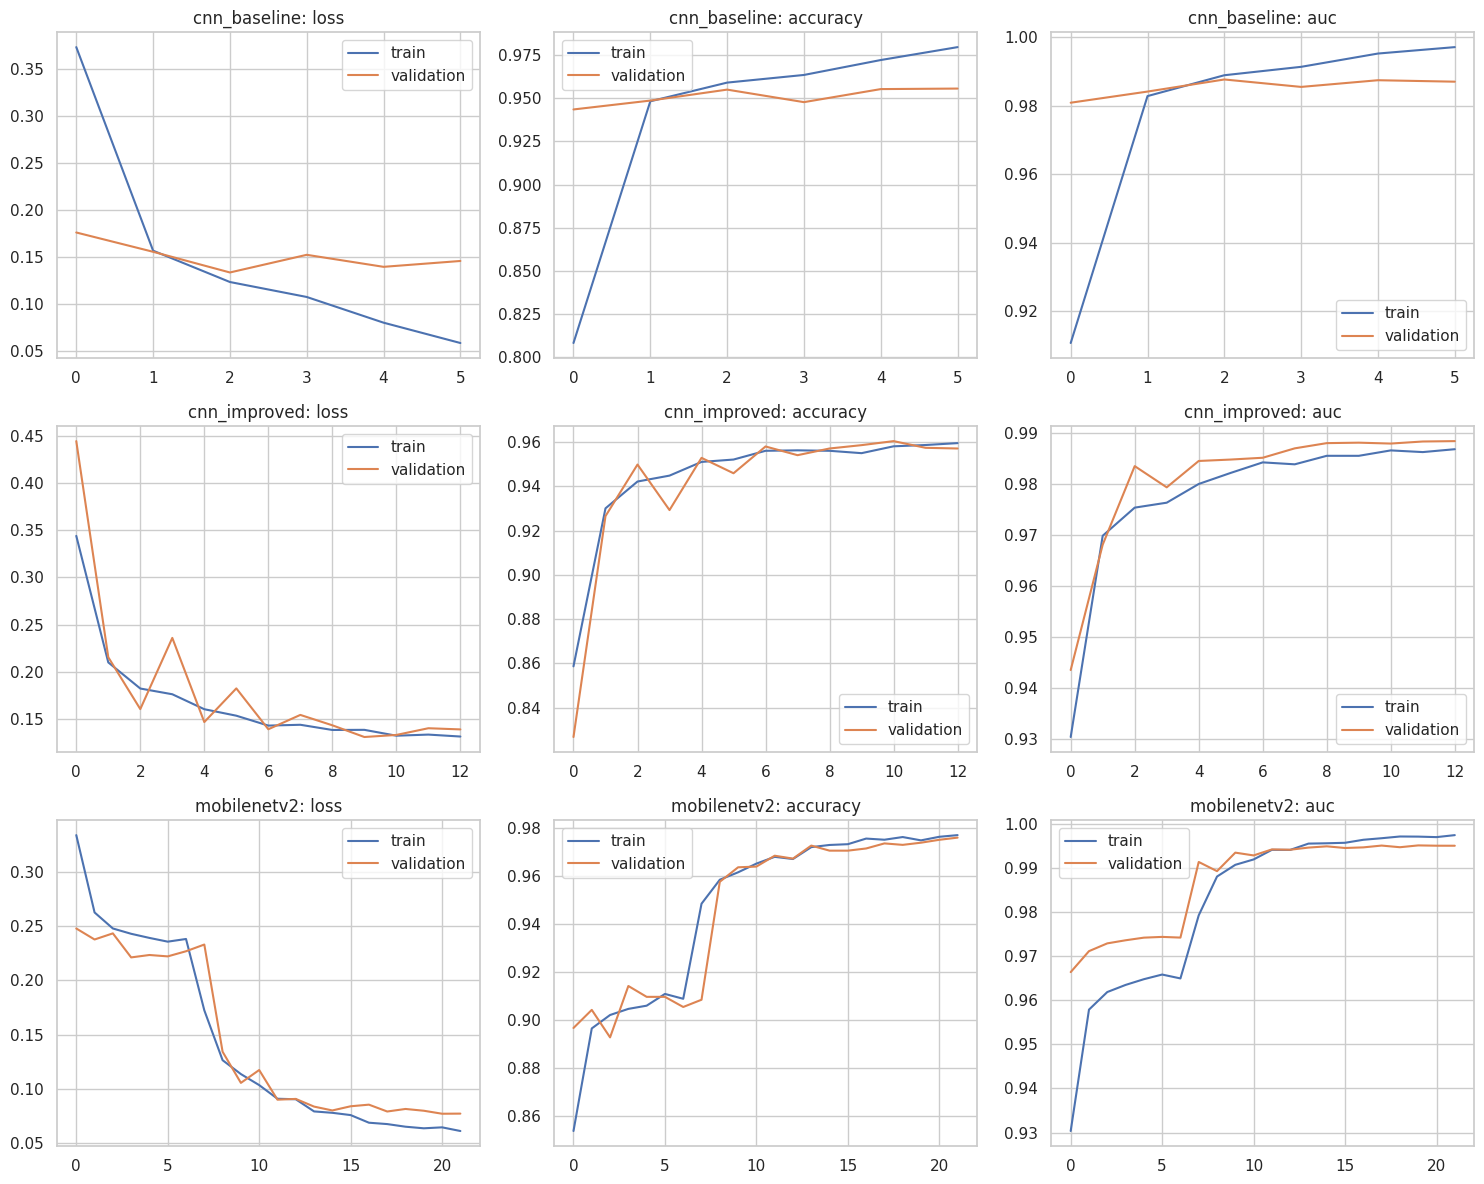

In [16]:
fig, axes = plt.subplots(len(histories), 3, figsize=(15, 4 * len(histories)))
for row, (name, history) in zip(axes, histories.items()):
    for ax, key in zip(row, ("loss", "accuracy", "auc")):
        ax.plot(history[key], label="train")
        ax.plot(history[f"val_{key}"], label="validation")
        ax.set_title(f"{name}: {key}")
        ax.legend()
plt.tight_layout()
plt.show()

The baseline CNN overfits: training accuracy reaches about 98% while validation stays near 95.5% and validation loss stops improving after the third epoch. The improved CNN keeps both curves together at about 96%. MobileNetV2 stays near 90% while the backbone is frozen and then jumps to about 97.6% once fine-tuning starts, with training and validation curves staying close, so the gain does not come from overfitting.

Validation F1 of each model. The highest one is the final model, so the test set is not used to choose it.

In [17]:
val_f1 = {name: M.evaluate_model(model, val_ds)["f1"] for name, model in models.items()}
final_name = max(val_f1, key=val_f1.get)
print("final model:", final_name)
pd.Series(val_f1).round(4)

final model: mobilenetv2


,0
cnn_baseline,0.9540
cnn_improved,0.9577
mobilenetv2,0.9751


Test-set evaluation with accuracy, precision, recall, F1 and ROC-AUC. Parasitized is the positive class.

In [18]:
results, predictions = {}, {}
for name, model in models.items():
    y_true, y_prob = M.collect_predictions(model, test_ds)
    predictions[name] = (y_true, y_prob)
    results[name] = M.compute_metrics(y_true, y_prob)

summary = pd.DataFrame(
    {n: {k: v for k, v in r.items() if k not in ("confusion_matrix", "n_samples")} for n, r in results.items()}
).T
summary.to_csv(config.MODELS_DIR / "model_comparison.csv")
summary.round(4)

,accuracy,precision,recall,f1,roc_auc
cnn_baseline,0.9568,0.9715,0.9412,0.9561,0.9873
cnn_improved,0.9593,0.9724,0.9456,0.9588,0.9894
mobilenetv2,0.9730,0.9762,0.9695,0.9729,0.9957


MobileNetV2 is clearly the best model on the test set, with accuracy 0.9730, recall 0.9695, F1 0.9729 and ROC-AUC 0.9957. Against the better CNN that is about 1.4 points more accuracy and 2.4 points more recall on parasitized cells. The two CNNs are close to each other, so augmentation and batch normalisation added only about a quarter of a point of accuracy.

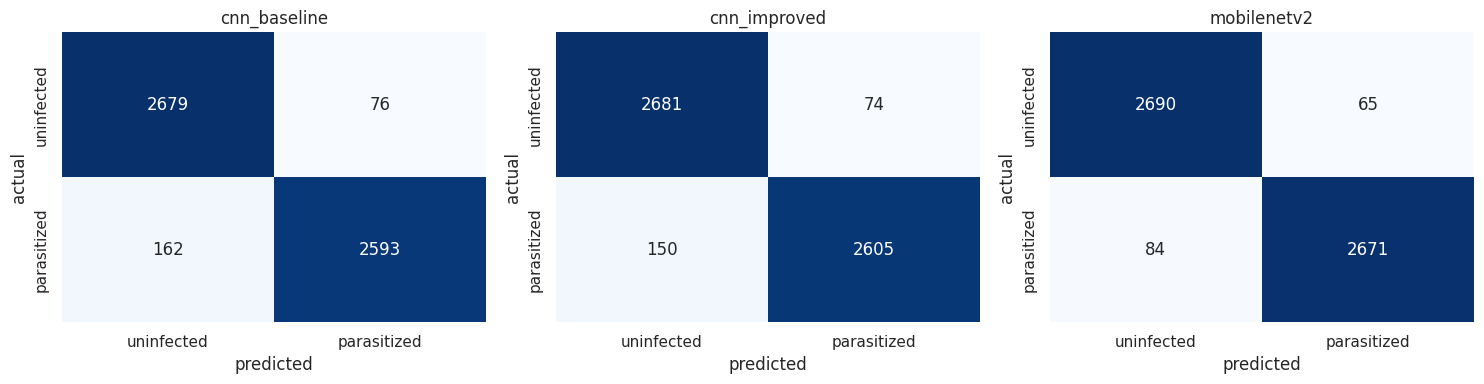

In [19]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (name, r) in zip(axes, results.items()):
    sns.heatmap(
        np.array(r["confusion_matrix"]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=config.CLASS_NAMES,
        yticklabels=config.CLASS_NAMES,
        ax=ax,
    )
    ax.set(title=name, xlabel="predicted", ylabel="actual")
plt.tight_layout()
plt.show()

MobileNetV2 misses 84 of the 2,755 parasitized test cells and raises 65 false alarms, compared with roughly 150 to 160 misses and about 75 false alarms for the two CNNs.

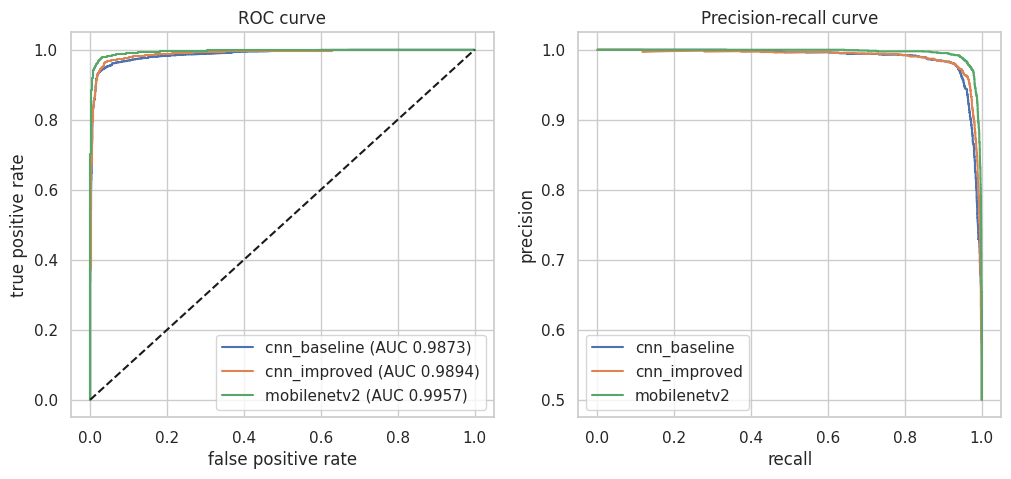

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (y_true, y_prob) in predictions.items():
    fpr, tpr, _ = skm.roc_curve(y_true, y_prob)
    precision, recall, _ = skm.precision_recall_curve(y_true, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {results[name]['roc_auc']:.4f})")
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
axes[1].set(title="Precision-recall curve", xlabel="recall", ylabel="precision")
axes[0].legend()
axes[1].legend()
plt.show()

MobileNetV2 sits above both CNNs through the low false-positive region of the ROC curve, and in the precision-recall plot it keeps its precision slightly longer as recall approaches one. The two CNN curves are almost identical.

In [21]:
y_true, y_prob = predictions[final_name]
print(skm.classification_report(y_true, (y_prob >= 0.5).astype(int), target_names=config.CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

  uninfected     0.9697    0.9764    0.9731      2755
 parasitized     0.9762    0.9695    0.9729      2755

    accuracy                         0.9730      5510
   macro avg     0.9730    0.9730    0.9730      5510
weighted avg     0.9730    0.9730    0.9730      5510



Precision and recall are balanced for both classes (between 0.970 and 0.976), so the model does not lean toward either class, which fits the balanced test set.

Effect of the decision threshold on the final model. Lowering it trades precision for recall on parasitized cells.

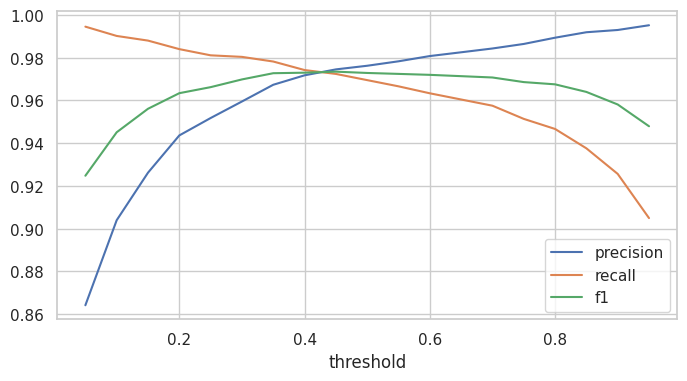

In [22]:
rows = []
for threshold in np.linspace(0.05, 0.95, 19):
    m = M.compute_metrics(y_true, y_prob, threshold)
    rows.append({"threshold": threshold, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"]})
pd.DataFrame(rows).set_index("threshold").plot(figsize=(8, 4))
plt.show()

F1 is nearly flat from about 0.35 to 0.7 and peaks near 0.4 at about 0.973, so the default threshold of 0.5 is already close to the best overall balance. Lowering it to 0.3 raises recall on parasitized cells to about 0.98 at a precision of about 0.96, a trade a screening setting might prefer.

Parasitized test cells the final model missed.

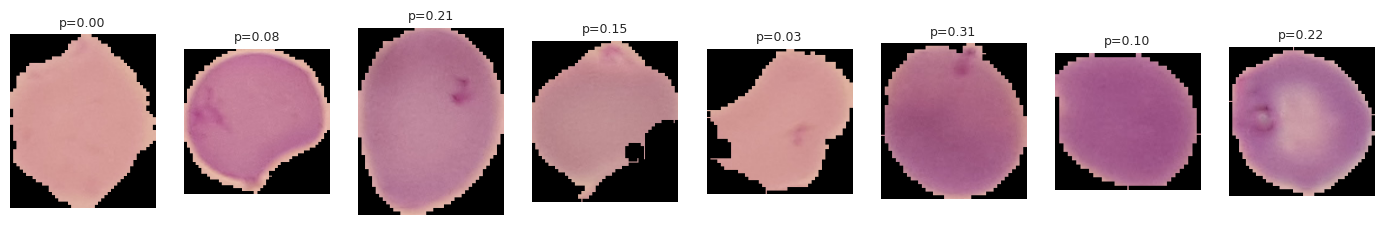

In [23]:
y_pred = (y_prob >= 0.5).astype(int)
missed = np.where((y_true == 1) & (y_pred == 0))[0][:8]
fig, axes = plt.subplots(1, max(len(missed), 1), figsize=(2.2 * max(len(missed), 1), 2.6), squeeze=False)
for ax, i in zip(axes[0], missed):
    ax.imshow(Image.open(test_paths[i]))
    ax.set_title(f"p={y_prob[i]:.2f}", fontsize=9)
    ax.axis("off")
plt.show()

Several missed cells carry only a faint or tiny spot at the edge, and two (p=0.00 and p=0.03) show no obvious parasite at all, which points to parasites too small to survive the resize or to label noise in the dataset. Most probabilities fall between 0.0 and 0.31, so these are confident misses rather than borderline calls.

The final model is registered as version 1 so the API can serve it and retraining can build on it.

In [24]:
version = R.register_model(models[final_name], results[final_name], name=final_name)
print(version, final_name, sorted(p.name for p in config.MODELS_DIR.iterdir()))

1 mobilenetv2 ['.gitkeep', 'malaria_v1.keras', 'model_comparison.csv', 'registry.json']


In [25]:
import shutil

shutil.make_archive("/content/models_export", "zip", config.MODELS_DIR)
files.download("/content/models_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

A small stratified sample of the data is exported so the deployed container can retrain and be evaluated without the full dataset.

In [ ]:
import random

sample_dir = Path("/content/data_sample")
rng = random.Random(config.SEED)
for subset, directory, n in (("train", config.TRAIN_DIR, 500), ("test", config.TEST_DIR, 300)):
    for name in config.CLASS_NAMES:
        dest = sample_dir / subset / name
        dest.mkdir(parents=True, exist_ok=True)
        for f in rng.sample(sorted((directory / name).glob("*.png")), n):
            shutil.copy2(f, dest / f.name)

shutil.make_archive("/content/data_sample", "zip", sample_dir)
files.download("/content/data_sample.zip")